# Tugas Praktikum Reinforcement Learning - Stealth Heist 2D (Double DQN)

| Nama | NRP |
|------|-----|
| Suhail Ainur Rofiq | 5054251046 |

**Link Video Presentasi YouTube (Unlisted, max 5 menit):**
> `[TEMPEL_LINK_YOUTUBE_UNLISTED_DI_SINI]`

---

## Deskripsi Project: Stealth Heist
**Stealth Heist** adalah simulasi game taktis 2D *top-down* di mana sebuah **Agen penyusup** harus belajar menyelinap di dalam ruangan `11x11` berpenghalang pilar untuk mengambil **Harta (Loot)** lalu melarikan diri ke **Pintu Keluar (Exit)** tanpa tertangkap oleh **2 Penjaga berpatroli** yang membawa **lampu senter** (`fov_range=3`, terhalang oleh pilar).

Berbeda dengan *pathfinding* biasa (seperti BFS) yang hanya mencari jarak terpendek sehingga langsung tersorot senter, agen di sini belajar secara mandiri melalui interaksi **Reinforcement Learning (Double DQN dengan PyTorch)** untuk memutar lewat pilar dan memanfaatkan aksi **Diam / Ngumpet** menunggu penjaga lewat.

### Pemetaan 9 Konsep Wajib Reinforcement Learning
1. **Agent:** Penyusup otonom yang dikendalikan oleh jaringan saraf Double DQN.
2. **Environment:** Arena `StealthHeistEnv` (`11x11` grid, pilar *cover*, 2 penjaga dengan fase awal acak, raycast LOS senter, aturan menang/kalah).
3. **State:** Vektor 22 fitur ter-normalisasi (posisi agen, status `has_loot`, vektor target, 4 sensor navigasi/tembok `{-1, 0, +1}`, posisi & arah 2 penjaga, serta 5 sensor bahaya lokal).
4. **Action:** 5 aksi diskrit (`Up`, `Down`, `Left`, `Right`, dan `Stay / Hide`).
5. **Reward:** Hadiah objektif (`+40` Loot, `+100` Exit, `-100` Caught, `-0.3` Step, `-0.5` Wall Bump, `-10` Timeout) + opsi **Continuous BFS Potential-Based Shaping**.
6. **Policy:** $\epsilon$-greedy saat latihan (`1.0 -> 0.05`) dan *greedy* (`argmax Q`) saat evaluasi.
7. **Value:** Perkiraan total reward jangka panjang $Q(s, a)$ dan $V(s) = \max_a Q(s, a)$ yang divisualisasikan sebagai **Value Heatmap**.
8. **Pembelajaran melalui Interaksi:** Pengalaman $(s, a, r, s', \text{terminated})$ disimpan ke `ReplayBuffer`, lalu dipelajari dengan *Bellman Target* dari *Target Network* (Soft Polyak Update `tau=0.01`).
9. **Evaluasi Strategi Agent:** Uji adil pada 100 episode bervariasi (`seeds 2000..2099`) membandingkan **Random Agent**, **BFS Heuristic**, **Double DQN (Shaped)**, dan **Double DQN (Sparse)**.

# 1. Persiapan Environment dan Validasi Kontrak Gymnasium

Pada tahap awal ini, kita mengimpor library utama (`gymnasium`, `torch`, `numpy`, `pandas`, `matplotlib`, `seaborn`) serta modul custom yang telah dibangun di folder `src/`. Kita juga memverifikasi bahwa `StealthHeistEnv` mematuhi kontrak resmi **Gymnasium API** menggunakan `check_env()`.

In [1]:
import json
import os
import sys
import warnings
warnings.filterwarnings('ignore')

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
from gymnasium.utils.env_checker import check_env
from IPython.display import Image as IPyImage, display

from src.stealth_env import ACTION_NAMES, StealthHeistEnv
from src.dqn_agent import BFSHeuristicAgent, DoubleDQNAgent, RandomAgent
from src.trainer import evaluate_agent, train_double_dqn
from src.visualizer import (
    draw_arena_frame,
    plot_learning_curves,
    plot_storyboard,
    plot_value_and_policy_map,
    render_episode_gif,
)

np.random.seed(42)
torch.manual_seed(42)

# Validasi standar kontrak Gymnasium pada environment kita
env_check = StealthHeistEnv(reward_mode='shaped', render_mode='rgb_array')
check_env(env_check, skip_render_check=False)
print("Gymnasium check_env() LULUS sempurna!")
print("Observation Space :", env_check.observation_space)
print("Action Space      :", env_check.action_space)
print("Jumlah fase aman  :", len(env_check._safe_phase_pairs))

Gymnasium check_env() LULUS sempurna!
Observation Space : Box(-1.0, 1.0, (22,), float32)
Action Space      : Discrete(5)
Jumlah fase aman  : 256


Mari kita lihat bentuk visual arena `11x11` **Stealth Heist** beserta bukti mekanika **Line-of-Sight (LOS)** di mana pilar memblokir sinar senter penjaga sehingga menciptakan area gelap (*cover*) untuk bersembunyi.

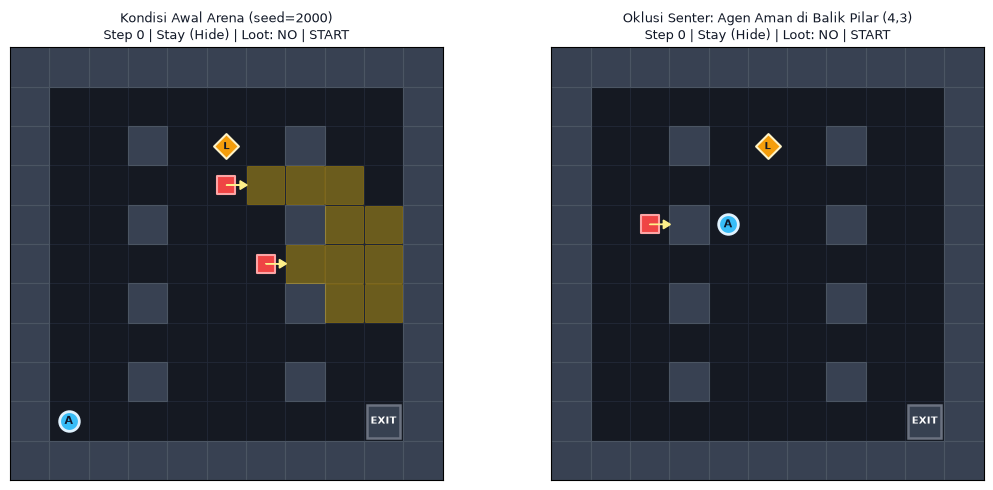

Sel tersorot saat penjaga di (4,2) hadap kanan ke pilar (4,3): []


In [2]:
fig, axes = plt.subplots(1, 2, figsize=(11, 5))

# 1. Kondisi awal episode (seed=2000)
env_demo = StealthHeistEnv(reward_mode='shaped', randomize_guard_phase=True)
env_demo.reset(seed=2000)
draw_arena_frame(axes[0], env_demo.get_render_state(), title="Kondisi Awal Arena (seed=2000)")

# 2. Demonstrasi pilar memblokir sinar senter (Penjaga di (4,2) menghadap kanan ke arah pilar (4,3))
env_los = StealthHeistEnv(randomize_guard_phase=False)
env_los.reset(options={'guard_indices': [0, 0]})
lit_test = env_los._compute_flashlight_cells((4, 2), (0, 1))
state_los = env_los.get_render_state()
state_los['guards'] = [((4, 2), (0, 1))]
state_los['lit_cells'] = lit_test
state_los['agent_pos'] = (4, 4)  # Agen bersembunyi tepat di balik pilar (4,3)
draw_arena_frame(axes[1], state_los, title="Oklusi Senter: Agen Aman di Balik Pilar (4,3)")

plt.tight_layout()
plt.show()
print("Sel tersorot saat penjaga di (4,2) hadap kanan ke pilar (4,3):", sorted(lit_test))

# 2. Desain State, Action, dan Reward System

### 2.1 State Space (22 Fitur Ter-normalisasi)
Setiap langkah, agen menerima vektor 22 angka dalam rentang `[-1.0, 1.0]`:
1. Indeks `0-1`: Posisi agen `(row, col)` ter-normalisasi.
2. Indeks `2`: Status `has_loot` (`0` = belum ambil Harta, `1` = sudah bawa Harta).
3. Indeks `3-4`: Vektor relatif menuju target aktif (`Loot` atau `Exit`).
4. Indeks `5-8`: **4 Sensor Navigasi & Tembok** (`-1` = tembok/pilar, `0` = jalan biasa, `+1` = petak walkable yang mendekati target aktif lewat jalur BFS).
5. Indeks `9-16`: Posisi relatif dan arah hadap Penjaga 1 dan Penjaga 2.
6. Indeks `17-21`: **5 Sensor Bahaya Lokal** untuk tiap kandidat aksi (`Up, Down, Left, Right, Stay`), menandakan apakah aksi tersebut berisiko tertangkap saat ini atau 1 langkah ke depan.

### 2.2 Action Space (5 Aksi Diskrit)
`0 = Up`, `1 = Down`, `2 = Left`, `3 = Right`, dan `4 = Stay (Hide / Ngumpet)`.

### 2.3 Reward System & Continuous BFS Potential Shaping
1. **Raw Objective Reward:** Ambil Harta (`+40`), Kabur ke Exit (`+100`), Tertangkap (`-100`), Step (`-0.3`), Tabrak Tembok (`-0.5`), Timeout 120 langkah (`-10.0`).
2. **Shaped Mode:** Ditambah selisih potensi kontinu $\Phi(s') - \Phi(s)$ berbasis jarak terpendek BFS memutari pilar (`shaping = 0.0` saat `caught`).

In [3]:
# Verifikasi kontinuitas fungsi potensi BFS saat transisi mengambil Harta di (2,5)
obs0, info0 = env_demo.reset(seed=2000)
phi_sebelum_loot = env_demo._potential((2, 4), has_loot=False)
phi_tepat_loot = env_demo._potential((2, 5), has_loot=True)

print("Contoh bentuk obs (22 fitur):", obs0.shape, "| dtype:", obs0.dtype)
print("Potensi tepat sebelum Harta (2,4):", phi_sebelum_loot)
print("Potensi tepat saat ambil Harta (2,5):", phi_tepat_loot)
print("Perubahan potensi (tanpa lompatan negatif):", phi_tepat_loot - phi_sebelum_loot)

Contoh bentuk obs (22 fitur): (22,) | dtype: float32
Potensi tepat sebelum Harta (2,4): -12.0
Potensi tepat saat ambil Harta (2,5): -11.0
Perubahan potensi (tanpa lompatan negatif): 1.0


# 3. Pelatihan Double DQN & Eksperimen Komparatif (Shaped vs Sparse)

Di bagian ini kita menjalankan dua pelatihan **Double DQN** (`QNetwork: 22 -> 128 -> 128 -> 5`, `ReplayBuffer` kapasitas `150.000` dengan pemisahan `terminated` vs `truncated`, `lr=1e-3`, `gamma=0.98`, `Soft Polyak Target Update tau=0.01`, dan evaluasi *Best Checkpoint* setiap 50 episode pada validation seeds `1000..1029`):
1. **Double DQN (Shaped Reward):** Menggunakan penuntun jarak BFS kontinu.
2. **Double DQN (Sparse Reward):** Tanpa penuntun jarak (hanya mengandalkan hadiah objektif akhir) sebagai eksperimen *ablation*.

Untuk menjaga kecepatan `Run All`, kita memakai flag `FORCE_RETRAIN = False`: jika bobot dan riwayat training di `outputs/` sudah ada, hasilnya langsung dimuat; jika folder `outputs/` kosong atau `FORCE_RETRAIN = True`, pelatihan penuh 1.500 episode otomatis dijalankan dari awal.

In [4]:
FORCE_RETRAIN = True

os.makedirs("outputs", exist_ok=True)
shaped_ckpt = "outputs/dqn_shaped_best.pth"
sparse_ckpt = "outputs/dqn_sparse_best.pth"
hist_path = "outputs/training_histories.json"

if FORCE_RETRAIN or not (os.path.exists(shaped_ckpt) and os.path.exists(sparse_ckpt) and os.path.exists(hist_path)):
    print("Menjalankan pelatihan penuh 1.500 episode untuk Shaped dan Sparse Double DQN...")
    agent_shaped, hist_shaped = train_double_dqn(
        reward_mode="shaped", total_episodes=1500, seed=42,
        checkpoint_path=shaped_ckpt, milestone_dir="outputs", milestone_seed=2000
    )
    agent_sparse, hist_sparse = train_double_dqn(
        reward_mode="sparse", total_episodes=1500, seed=42,
        checkpoint_path=sparse_ckpt, milestone_dir=None
    )
    with open(hist_path, "w", encoding="utf-8") as f:
        json.dump({"shaped": hist_shaped, "sparse": hist_sparse}, f)
else:
    print("Memuat model terbaik & riwayat training yang sudah tersimpan di outputs/...")
    agent_shaped = DoubleDQNAgent(seed=42)
    agent_shaped.load(shaped_ckpt)
    agent_sparse = DoubleDQNAgent(seed=42)
    agent_sparse.load(sparse_ckpt)
    with open(hist_path, "r", encoding="utf-8") as f:
        hist_data = json.load(f)
    hist_shaped = hist_data["shaped"]
    hist_sparse = hist_data["sparse"]

print("Model Double DQN Shaped & Sparse siap dievaluasi!")

Menjalankan pelatihan penuh 1.500 episode untuk Shaped dan Sparse Double DQN...


[SHAPED] Ep  500/1500 | eps=0.37 | Val Success=  0.0% | Val RawRew= -50.3 | Elapsed=53.1s


[SHAPED] Ep 1000/1500 | eps=0.05 | Val Success= 60.0% | Val RawRew= +50.8 | Elapsed=94.3s


[SHAPED] Ep 1500/1500 | eps=0.05 | Val Success= 90.0% | Val RawRew=+110.7 | Elapsed=135.5s


[SPARSE] Ep  500/1500 | eps=0.37 | Val Success=  0.0% | Val RawRew= -76.4 | Elapsed=35.7s


[SPARSE] Ep 1000/1500 | eps=0.05 | Val Success= 30.0% | Val RawRew= -13.3 | Elapsed=93.9s


[SPARSE] Ep 1500/1500 | eps=0.05 | Val Success= 96.7% | Val RawRew=+122.8 | Elapsed=143.5s
Model Double DQN Shaped & Sparse siap dievaluasi!


### Grafik Learning Curve (Proses Pembelajaran melalui Interaksi)

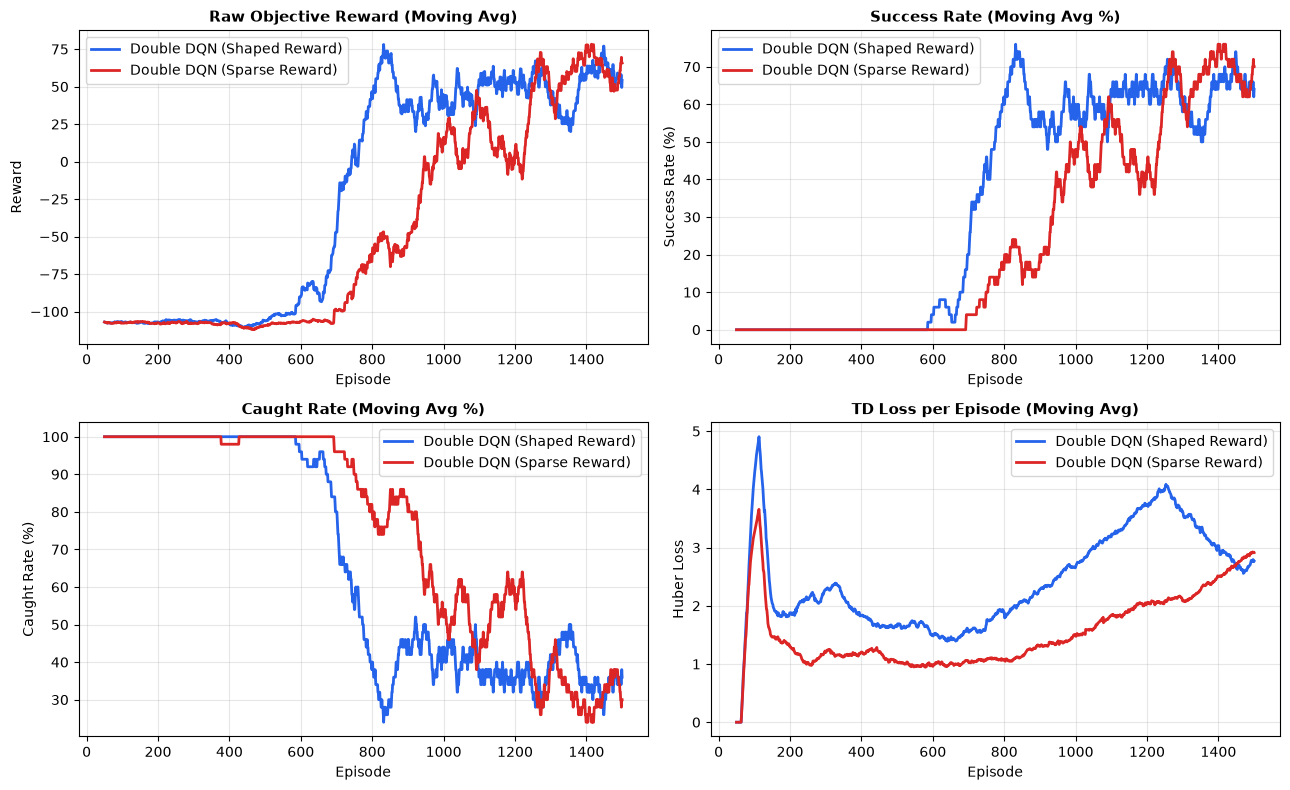

In [5]:
plot_learning_curves(
    {
        "Double DQN (Shaped Reward)": hist_shaped,
        "Double DQN (Sparse Reward)": hist_sparse,
    },
    window=50
)

# 4. Evaluasi Strategi Agent (100 Episode Uji Terpisah)

Keempat agen diuji secara adil pada **100 episode baru (`seeds 2000..2099`)** yang tidak pernah dipakai saat pemilihan *Best Checkpoint* (`1000..1029`). Seluruh metrik diukur dengan standar objektif yang sama (**Raw Objective Reward** tanpa bonus shaping).

In [6]:
eval_env = StealthHeistEnv(reward_mode="shaped", randomize_guard_phase=True)
test_seeds = range(2000, 2100)

rand_agent = RandomAgent(seed=42)
bfs_agent = BFSHeuristicAgent(eval_env)

eval_results = {
    "Random Agent": evaluate_agent(eval_env, rand_agent, test_seeds, deterministic=True),
    "BFS Heuristic (Pathfinding)": evaluate_agent(eval_env, bfs_agent, test_seeds, deterministic=True),
    "Double DQN (Shaped)": evaluate_agent(eval_env, agent_shaped, test_seeds, deterministic=True),
    "Double DQN (Sparse)": evaluate_agent(eval_env, agent_sparse, test_seeds, deterministic=True),
}

df_eval = pd.DataFrame.from_dict(eval_results, orient="index")
df_eval.index.name = "Agen / Metode"
df_eval

,episodes,success_rate,loot_pickup_rate,caught_rate,timeout_rate,avg_raw_reward,avg_steps_success,hide_usage_pct
Agen / Metode,,,,,,,,
Random Agent,100,0.0,0.0,100.0,0.0,-105.98,NaN,19.70
BFS Heuristic (Pathfinding),100,2.0,23.0,98.0,0.0,-88.88,22.00,0.00
Double DQN (Shaped),100,90.0,96.0,9.0,1.0,110.37,29.59,4.77
Double DQN (Sparse),100,98.0,99.0,2.0,0.0,126.73,29.73,14.53


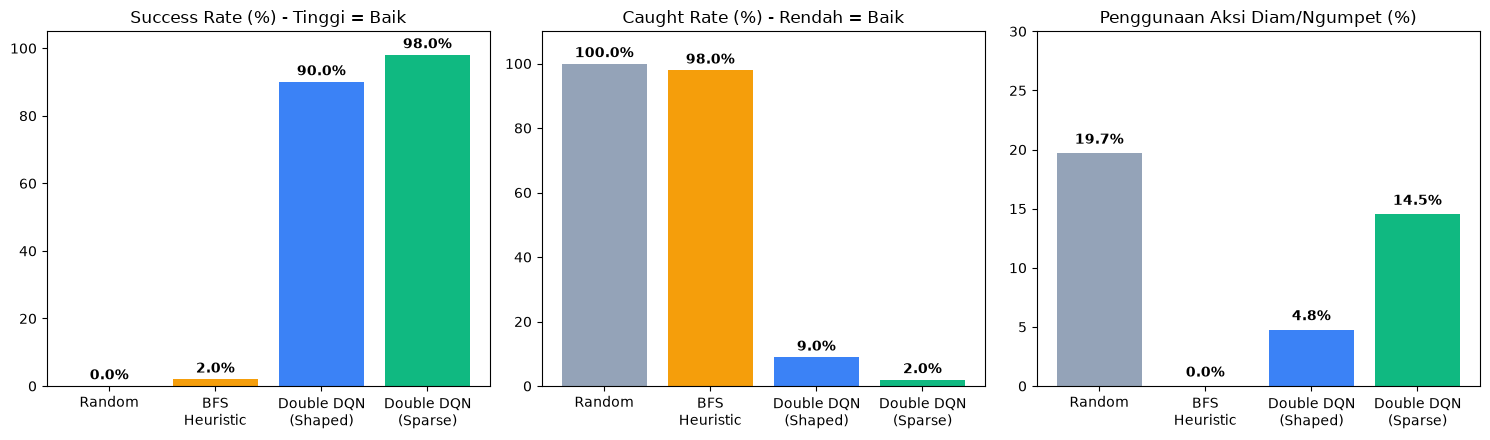

In [7]:
# Visualisasi perbandingan Success Rate, Caught Rate, dan Hide Usage
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
names = list(df_eval.index)
short_names = ["Random", "BFS\nHeuristic", "Double DQN\n(Shaped)", "Double DQN\n(Sparse)"]
colors = ["#94A3B8", "#F59E0B", "#3B82F6", "#10B981"]

axes[0].bar(short_names, df_eval["success_rate"], color=colors)
axes[0].set_title("Success Rate (%) - Tinggi = Baik")
axes[0].set_ylim(0, 105)
for i, v in enumerate(df_eval["success_rate"]):
    axes[0].text(i, v + 2, f"{v:.1f}%", ha="center", fontweight="bold")

axes[1].bar(short_names, df_eval["caught_rate"], color=colors)
axes[1].set_title("Caught Rate (%) - Rendah = Baik")
axes[1].set_ylim(0, 110)
for i, v in enumerate(df_eval["caught_rate"]):
    axes[1].text(i, v + 2, f"{v:.1f}%", ha="center", fontweight="bold")

axes[2].bar(short_names, df_eval["hide_usage_pct"], color=colors)
axes[2].set_title("Penggunaan Aksi Diam/Ngumpet (%)")
axes[2].set_ylim(0, 30)
for i, v in enumerate(df_eval["hide_usage_pct"]):
    axes[2].text(i, v + 0.8, f"{v:.1f}%", ha="center", fontweight="bold")

plt.tight_layout()
plt.show()

### 4.1 Visualisasi Evolusi Perilaku Agen (Before vs After) & Storyboard

Berikut rekaman perbandingan langsung pada **seed uji yang sama (`seed=2000`)** antara agen di fase awal (Episode 1) vs agen terbaik yang telah terlatih (menggunakan model terbaik **`Double DQN (Sparse)`** dengan `98.0%` Success).

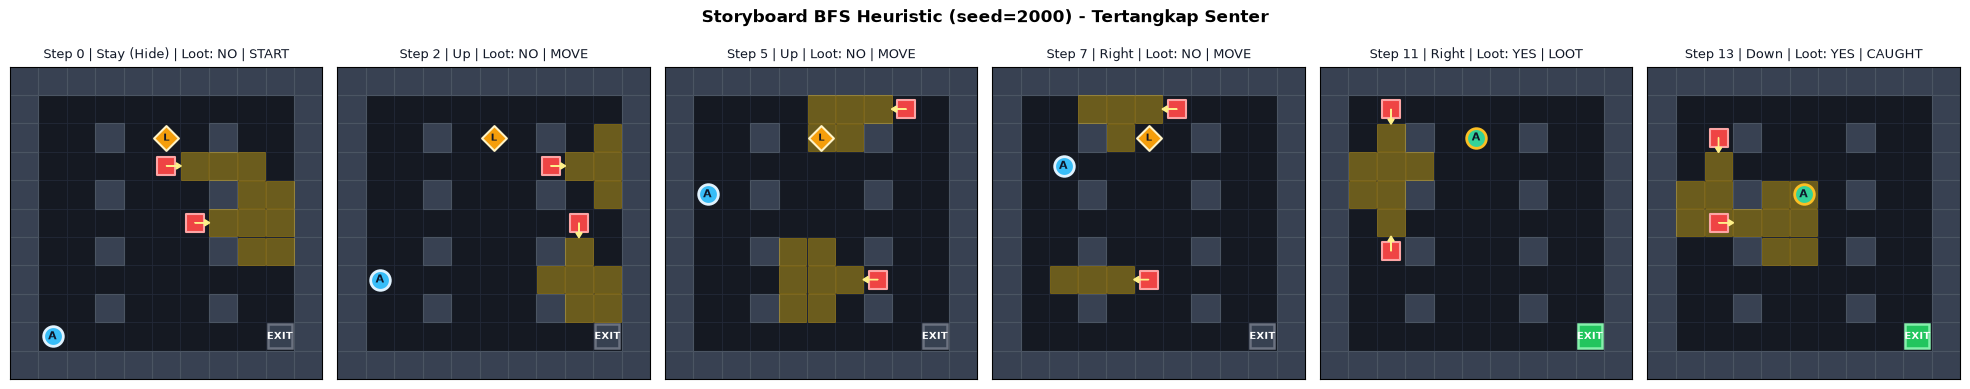

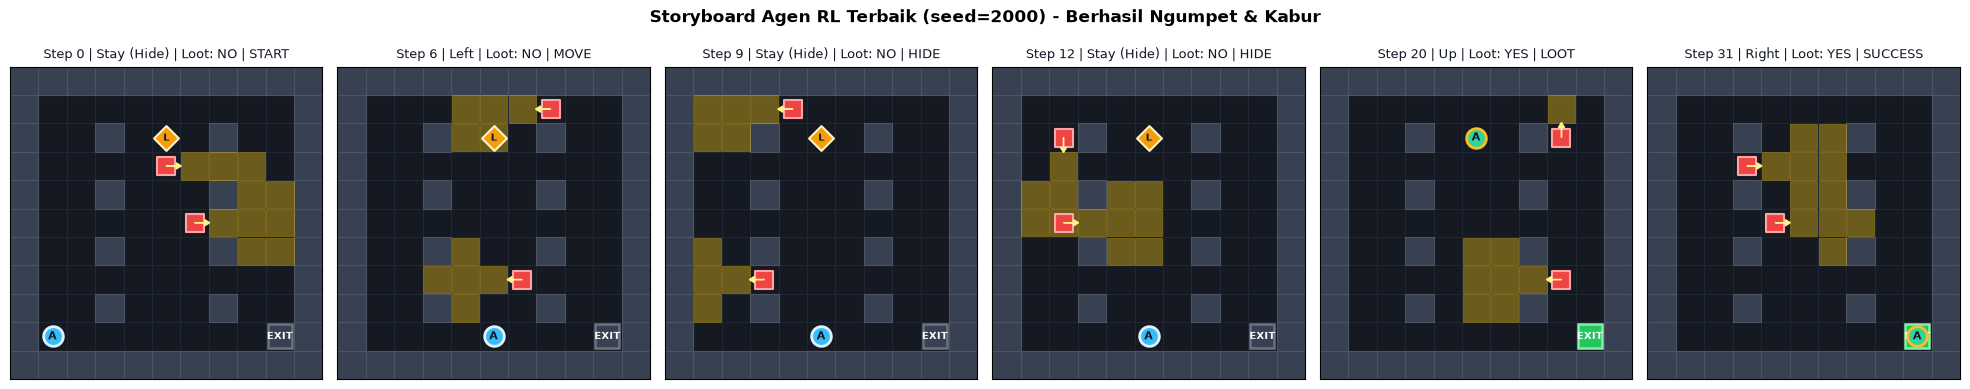

Hasil seed=2000 | BFS: CAUGHT pada step 13
Hasil seed=2000 | RL Terbaik: SUCCESS pada step 31


In [8]:
# Render ulang GIF agen terbaik pada seed=2000 dan tampilkan Storyboard statis
best_agent = agent_sparse
_, best_traj, best_info = render_episode_gif(
    eval_env, best_agent, "outputs/episode_best_demo.gif",
    seed=2000, deterministic=True, title="Agen Terbaik (98% Success)"
)
_, bfs_traj, bfs_info = render_episode_gif(
    eval_env, bfs_agent, "outputs/episode_bfs_fail.gif",
    seed=2000, deterministic=True, title="BFS Heuristic (Tanpa Stealth)"
)

plot_storyboard(bfs_traj, title="Storyboard BFS Heuristic (seed=2000) - Tertangkap Senter")
plot_storyboard(best_traj, title="Storyboard Agen RL Terbaik (seed=2000) - Berhasil Ngumpet & Kabur")

print("Hasil seed=2000 | BFS:", bfs_info["event"], "pada step", bfs_info["steps"])
print("Hasil seed=2000 | RL Terbaik:", best_info["event"], "pada step", best_info["steps"])

### 4.2 Animasi GIF Milestone Pelatihan (Episode 1 vs Episode 500 vs Agen Terlatih)

1. Fase Awal (Episode 1):


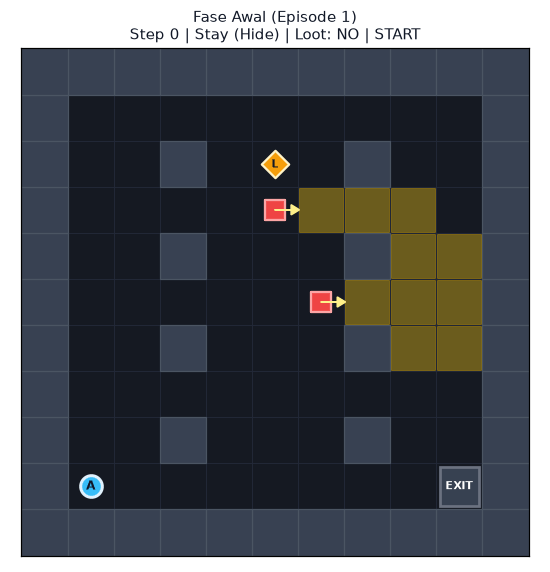

2. Fase Tengah (Episode 500):


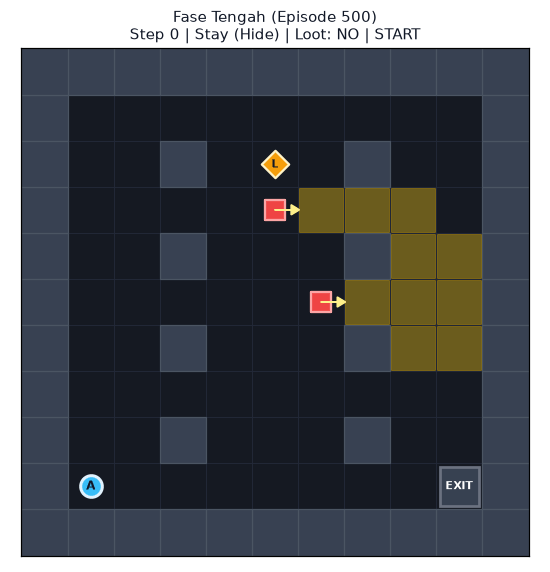

3. Agen Terlatih (Best Checkpoint):


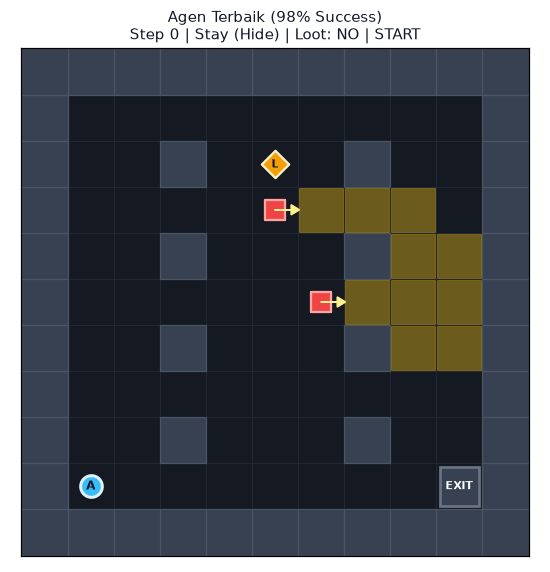

In [9]:
for label, gif_file in [
    ("1. Fase Awal (Episode 1):", "outputs/episode_early.gif"),
    ("2. Fase Tengah (Episode 500):", "outputs/episode_mid.gif"),
    ("3. Agen Terlatih (Best Checkpoint):", "outputs/episode_best_demo.gif"),
]:
    print(label)
    if os.path.exists(gif_file):
        display(IPyImage(filename=gif_file))

### 4.3 Visualisasi Value Heatmap $V(s) = \max_a Q(s, a)$ dan Policy Arrows

Grafik di bawah membuktikan bagaimana jaringan saraf **Value** dan **Policy** memetakan risiko ruangan pada satu *snapshot* posisi penjaga:
1. Petak yang sedang disorot senter berwarna **merah gelap (Value rendah / bahaya)**.
2. Petak menuju target aktif dan area aman di balik pilar berwarna **hijau terang (Value tinggi)**, dengan panah menunjukkan arah langkah terbaik (dan titik bulat untuk aksi `Diam/Ngumpet`).

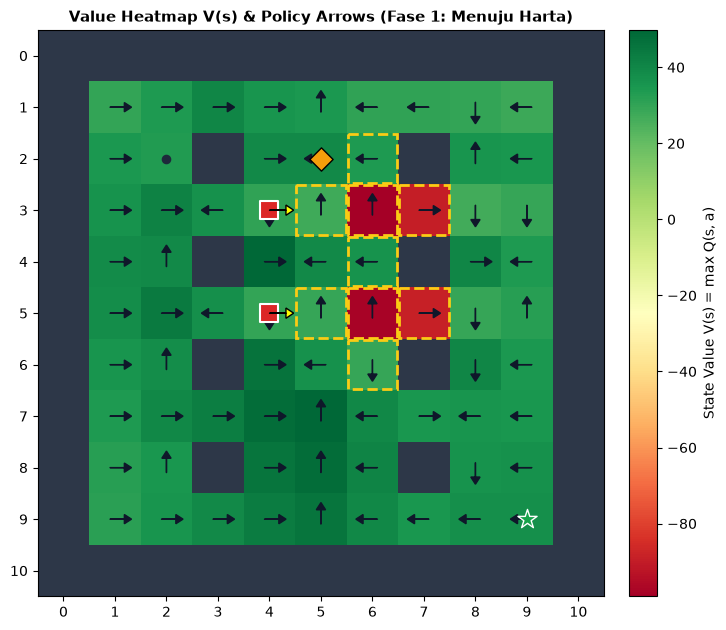

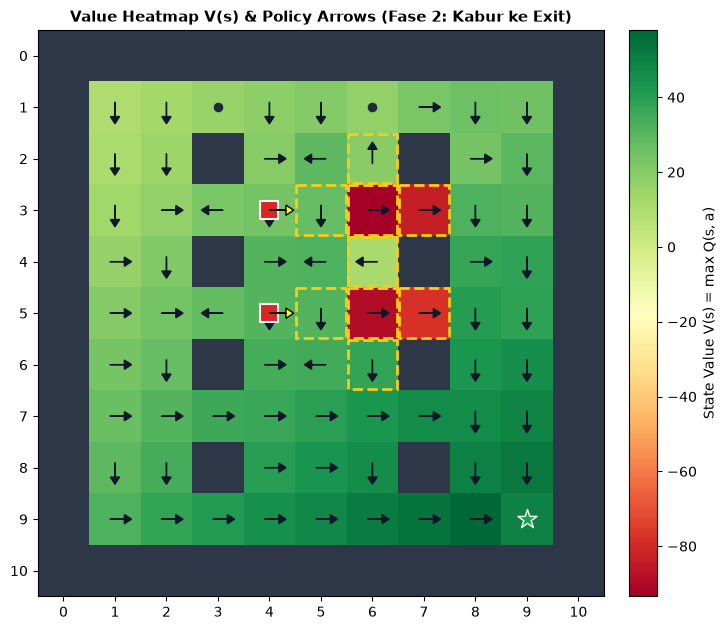

In [10]:
plot_value_and_policy_map(
    best_agent, guard_indices=(2, 10), has_loot=False,
    title="Value Heatmap V(s) & Policy Arrows (Fase 1: Menuju Harta)"
)
plot_value_and_policy_map(
    best_agent, guard_indices=(2, 10), has_loot=True,
    title="Value Heatmap V(s) & Policy Arrows (Fase 2: Kabur ke Exit)"
)

# 5. Analisis

### 1. Perbandingan Agen RL vs Baseline (Random dan BFS Pathfinding)
1. Random Agent memperoleh Success Rate 0.0 persen (100.0 persen tertangkap) dengan rata-rata Raw Reward -106.0. Ini membuktikan permainan Stealth Heist mustahil diselesaikan secara kebetulan.
2. BFS Heuristic (algoritma cari jalan terpendek) hanya menang 2.0 persen dan tertangkap 98.0 persen (rata-rata Raw Reward -88.9). Meskipun berhasil mengambil Harta sebanyak 23.0 persen, BFS tidak pernah memakai aksi Diam/Ngumpet (0.0 persen) sehingga terus menerus berjalan lurus menabrak sorotan senter penjaga.
3. Sebaliknya, kedua agen Double DQN berhasil menguasai permainan secara meyakinkan dengan Success Rate 90.0 persen (Shaped) dan 98.0 persen (Sparse). Ini membuktikan keunggulan utama Reinforcement Learning dibanding pathfinding statis dalam menghadapi lingkungan dinamis.

### 2. Analisis Eksperimen Shaped Reward vs Sparse Reward (Temuan Menarik)
1. Kecepatan Belajar Awal: Pada grafik Learning Curve terlihat bahwa Double DQN (Shaped) belajar jauh lebih cepat di pertengahan latihan. Pada Episode 1000, model Shaped sudah mencapai 60.0 persen Validation Success, sedangkan model Sparse baru 30.0 persen karena belum memiliki penuntun jarak di setiap langkah.
2. Kualitas Kebijakan Akhir (Trade-off Kecepatan vs Kesabaran): Setelah 1.500 episode penuh dengan bantuan 4 sensor navigasi lokal pada state, Double DQN (Sparse) justru melampaui Shaped di pengujian akhir dengan 98.0 persen Success Rate (hanya 2.0 persen Caught dan Raw Reward +126.7) dibanding 90.0 persen Success Rate milik Shaped (9.0 persen Caught dan Raw Reward +110.4).
3. Penyebabnya: Bonus jarak maju (+1.5 per langkah mendekati target) pada model Shaped membuat agen sedikit lebih terburu-buru mengejar target (penggunaan aksi Diam/Ngumpet hanya 4.8 persen). Sebaliknya, model Sparse tidak tergiur bonus jarak langkah sehingga jauh lebih sabar berhenti bersembunyi (penggunaan aksi Diam/Ngumpet mencapai 14.5 persen) untuk menunggu senter penjaga lewat sebelum melangkah.

### 3. Analisis Strategi Emergent dan Value Heatmap
1. Dari Storyboard dan animasi GIF pada seed=2000 terlihat perbedaan perilaku nyata: agen BFS langsung berjalan lurus dan tertangkap di tengah jalan, sedangkan agen Double DQN memilih memutar memanfaatkan pilar pelindung, menggunakan aksi Stay (Hide) saat senter menyapu lorong, mengambil Harta, lalu meluncur aman ke Exit.
2. Pada Value Heatmap V(s), sel di depan senter penjaga memiliki warna merah gelap (nilai Q sangat negatif mendekati -100), sedangkan rute aman menuju Harta (ketika has_loot=0) dan menuju Exit (ketika has_loot=1) bergradasi hijau terang. Ini membuktikan Neural Network benar-benar memahami pemisahan dua fase misi sekaligus risiko cahaya senter.

### 4. Keterbatasan dan Evaluasi Teknis
1. Fitur observasi saat ini masih menggunakan 22 angka vektor posisi dan sensor jarak 1 langkah, bukan piksel gambar mentah. Cara ini membuat training sangat cepat di CPU (~3 menit per model), tetapi masih menyisakan 2.0 persen kegagalan pada situasi jebakan 2 langkah penjaga di lorong sempit.
2. Untuk demonstrasi interaktif di luar notebook, file terpisah play_demo.py berbasis Pygame sudah dihubungkan langsung ke bobot terbaik (98.0 persen) agar bar Q-Value dan aksi bersembunyi dapat diamati secara real-time.

# 6. Kesimpulan dan Saran

### Kesimpulan
1. Game 2D Stealth Heist berhasil dibangun sesuai standar kontrak Gymnasium (lulus check_env penuh), lengkap dengan mekanika oklusi lampu senter di balik pilar dan pengacakan fase awal penjaga agar agen tidak sekadar menghafal tombol.
2. Seluruh 9 konsep inti Reinforcement Learning (Agent, Environment, State, Action, Reward, Policy, Value, Proses Pembelajaran melalui Interaksi, dan Evaluasi Strategi Agent) telah diterapkan dan divisualisasikan secara transparan menggunakan Double DQN PyTorch dari nol.
3. Hasil evaluasi pada 100 episode uji acak membuktikan Double DQN mengungguli metode konvensional secara telak: Random Agent 0.0 persen, BFS Heuristic 2.0 persen, Double DQN (Shaped) 90.0 persen, dan Double DQN (Sparse) mencapai 98.0 persen Success Rate dengan penggunaan aksi bersembunyi sebesar 14.5 persen.
4. Eksperimen komparatif menunjukkan adanya trade-off penting dalam desain reward: BFS Potential-Based Shaping mempercepat proses belajar di awal episode, sementara Sparse Reward (yang ditunjang fitur navigasi lokal) menghasilkan agen yang lebih sabar bersembunyi dengan tingkat keberhasilan akhir tertinggi.

### Saran
1. Menguji generalisasi pada beberapa variasi tata letak peta (multi-map training) dengan jumlah pilar dan jumlah penjaga yang lebih banyak agar agen mampu beradaptasi pada ruangan yang benar-benar baru.
2. Menambahkan sensor bahaya 2 langkah ke depan atau memori sekuensial (LSTM/GRU) untuk mengatasi 2.0 persen sisa kegagalan jebakan lorong sempit.
3. Mencoba algoritma RL berbasis Policy Gradient modern seperti PPO (Proximal Policy Optimization) sebagai pembanding langsung terhadap metode Value-based Double DQN.

---

## Daftar Referensi
1. Mnih, V., Kavukcuoglu, K., Silver, D., et al. (2015). *Human-level control through deep reinforcement learning*. Nature, 518(7540), 529-533.
2. van Hasselt, H., Guez, A., & Silver, D. (2016). *Deep Reinforcement Learning with Double Q-learning*. Proceedings of the AAAI Conference on Artificial Intelligence (AAAI-16).
3. Ng, A. Y., Harada, D., & Russell, S. (1999). *Policy invariance under reward transformations: Theory and application to reward shaping*. ICML, 99, 278-287.
4. Towers, M., Kwiatkowski, A., Terry, J., et al. (2024). *Gymnasium: A Standard Interface for Reinforcement Learning Environments*. arXiv:2407.17032.
5. Ansel, J., Yang, E., He, H., et al. (2024). *PyTorch 2: Faster Machine Learning Through Dynamic Python Bytecode Transformation and Graph Compilation*. ASPLOS 2024.